# Medicare Inpatient Pricing & Payment Analysis (DY2023)
**Audience:** hospital finance leadership and revenue-cycle teams. **Question:** how large is the gap between
what hospitals list as charges and what they are paid, what drives it, and which levers are real?

This notebook covers data cleaning, EDA, the driver analysis, hospital segmentation and the
documentation-capture screen. All business metrics come from the SQL views in `sql/02_views.sql`
so Python, Excel and Power BI agree to the dollar.

In [1]:
import sqlite3, re, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = ROOT / "data" / "healthcare.db"
if not DB.exists():                       # build the database on first run
    subprocess.run([sys.executable, str(ROOT / "python" / "build_database.py")], check=True)
con = sqlite3.connect(DB)
q = lambda sql: pd.read_sql(sql, con)
FIG = ROOT / "docs" / "images"; FIG.mkdir(parents=True, exist_ok=True)
OUT = ROOT / "data" / "processed"; OUT.mkdir(parents=True, exist_ok=True)

# One accent hue + neutral greys; text stays in ink colour (monochrome style).
INK, MUTED, GRID, ACCENT, LIGHT = "#1f2937", "#6b7280", "#e5e7eb", "#1d4e89", "#9db7d5"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110})
B = FuncFormatter(lambda v, _: f"${v/1e9:,.0f}B")

def sql_block(name):                       # run a named block from sql/03_analysis_queries.sql
    txt = (ROOT / "sql" / "03_analysis_queries.sql").read_text()
    blocks = dict(re.findall(r"-- name: (\w+)\n(.*?)(?=\n-- name:|\Z)", txt, flags=re.S))
    return q(blocks[name])

## 1. Data cleaning and quality log

In [2]:
raw = pd.read_csv(ROOT / "data/raw/MUP_INP_RY25_P03_V10_DY23_PrvSvc.CSV", encoding="cp1252",
                  dtype={"Rndrng_Prvdr_CCN": str, "DRG_Cd": str})
f = q("SELECT * FROM v_fact")
log = pd.DataFrame([
 ("Rows in raw CMS file", f"{len(raw):,}", "Grain = hospital x MS-DRG"),
 ("Rows loaded to fact table", f"{len(f):,}", "No rows dropped"),
 ("Duplicate hospital-DRG keys", f"{raw.duplicated(['Rndrng_Prvdr_CCN','DRG_Cd']).sum()}", "Primary key holds"),
 ("Hospitals / DRGs / states", f"{raw.Rndrng_Prvdr_CCN.nunique():,} / {raw.DRG_Cd.nunique()} / {raw.Rndrng_Prvdr_State_Abrvtn.nunique()}", "50 states + DC"),
 ("Missing RUCA (rural-urban) code", f"{raw.Rndrng_Prvdr_RUCA.isna().sum()} rows", "Kept; shown as 'Unclassified'"),
 ("CCN kept as 6-character text", "all 6 chars" if raw.Rndrng_Prvdr_CCN.str.len().eq(6).all() else "CHECK", "First two digits = state; leading zero must survive"),
 ("Rows with payment > charge", f"{int(f.payment_exceeds_charge.sum())} ({f.payment_exceeds_charge.mean():.2%})", "Kept and flagged; 0.19% of rows, 0.16% of discharges (see below)"),
 ("Minimum discharges per row", f"{int(f.total_discharges.min())}", "CMS suppresses cells of 10 or fewer"),
 ("DRG titles cut by CMS 88-char limit", f"{(raw.drop_duplicates('DRG_Cd').DRG_Desc.str.len() >= 88).sum()} of {raw.DRG_Cd.nunique()}", "Not used for tiering"),
], columns=["Check", "Result", "Treatment"])
log

,Check,Result,Treatment
0,Rows in raw CMS file,"146,427",Grain = hospital x MS-DRG
1,Rows loaded to fact table,"146,427",No rows dropped
2,Duplicate hospital-DRG keys,0,Primary key holds
3,Hospitals / DRGs / states,"2,945 / 534 / 51",50 states + DC
4,Missing RUCA (rural-urban) code,4 rows,Kept; shown as 'Unclassified'
5,CCN kept as 6-character text,all 6 chars,First two digits = state; leading zero must su...
6,Rows with payment > charge,281 (0.19%),"Kept and flagged; 0.19% of rows, 0.16% of disc..."
7,Minimum discharges per row,11,CMS suppresses cells of 10 or fewer
8,DRG titles cut by CMS 88-char limit,33 of 534,Not used for tiering


In [3]:
flag = f[f.payment_exceeds_charge == 1]
print(f"{len(flag)} rows where payment exceeds charges: {flag.total_discharges.sum():,} discharges = "
      f"{flag.total_discharges.sum()/f.total_discharges.sum():.2%} of volume, "
      f"${(flag.total_payment-flag.total_charges).sum()/1e6:,.0f}M net 'negative gap' "
      f"vs ${f.charge_gap.sum()/1e9:,.0f}B total gap.")

281 rows where payment exceeds charges: 7,701 discharges = 0.16% of volume, $77M net 'negative gap' vs $344B total gap.


Payment above charges happens on 281 low-volume rows. They are
immaterial in dollars, so they are **kept and flagged** rather than dropped, and all totals are sums of dollars, never averages of ratios.

## 2. Headline KPIs

In [4]:
k = sql_block("q1_headline_kpis").iloc[0]
print(f"Charges ${k.total_charges/1e9:,.0f}B | Payments ${k.total_payment/1e9:,.0f}B | Gap ${k.charge_gap/1e9:,.0f}B")
print(f"Payment-to-charge ratio {k.payment_to_charge_ratio:.1%} | Medicare share of payment {k.medicare_share_of_payment:.1%} | "
      f"Payment per discharge ${k.payment_per_discharge:,.0f}")

Charges $432B | Payments $88B | Gap $344B
Payment-to-charge ratio 20.5% | Medicare share of payment 83.0% | Payment per discharge $17,824


## 3. EDA: skew and why ratios must be volume-weighted

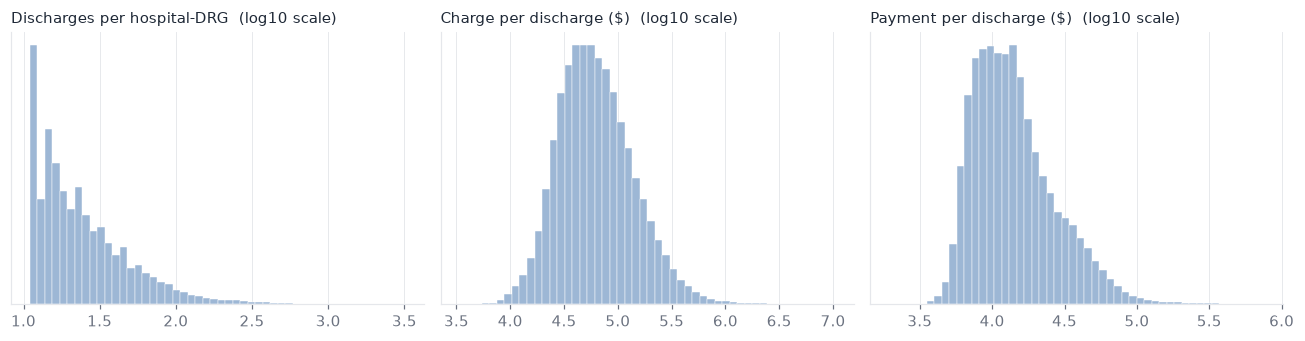

Simple average of row ratios = 26.2%  vs volume-weighted PCR = 20.5%  -> weight by dollars.


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, col, t in zip(ax, ["total_discharges", "avg_submitted_charge", "avg_total_payment"],
                     ["Discharges per hospital-DRG", "Charge per discharge ($)", "Payment per discharge ($)"]):
    a.hist(np.log10(f[col]), bins=50, color=LIGHT, edgecolor="white", linewidth=.3)
    a.set_title(t + "  (log10 scale)", loc="left", fontsize=10, color=INK); a.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / "01_distributions.png", bbox_inches="tight"); plt.show()
unw = (f.avg_total_payment / f.avg_submitted_charge).mean()
print(f"Simple average of row ratios = {unw:.1%}  vs volume-weighted PCR = {k.payment_to_charge_ratio:.1%}  -> weight by dollars.")

## 4. Concentration: where is the gap?

,entity,total,to_25pct,to_50pct,to_80pct
0,hospitals,2945,64,240,717
1,DRGs,534,5,25,83


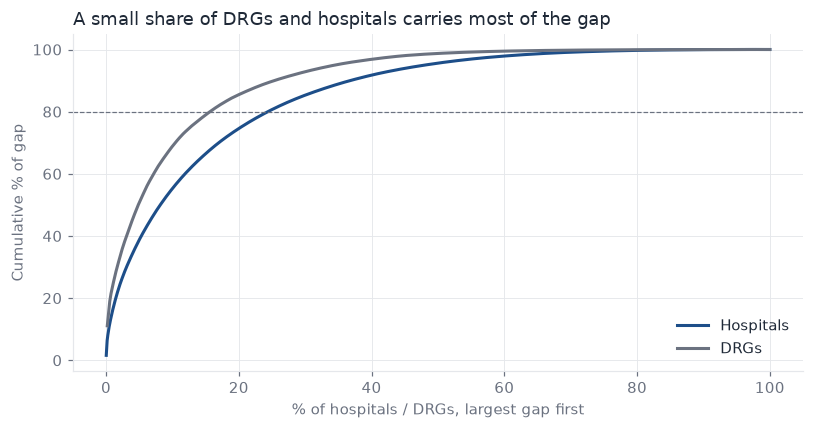

In [6]:
conc = sql_block("q2b_concentration_thresholds"); display(conc)
prov = q("SELECT * FROM v_provider_kpis"); drg = q("SELECT * FROM v_drg_kpis")
fig, ax = plt.subplots(figsize=(7.5, 4))
for d, lab, c in [(prov, "Hospitals", ACCENT), (drg, "DRGs", MUTED)]:
    s = d.charge_gap.sort_values(ascending=False).cumsum() / d.charge_gap.sum()
    ax.plot(np.arange(1, len(s) + 1) / len(s) * 100, s.values * 100, color=c, lw=2, label=lab)
ax.axhline(80, color=MUTED, lw=.8, ls="--"); ax.legend(frameon=False, loc="lower right")
ax.set_xlabel("% of hospitals / DRGs, largest gap first"); ax.set_ylabel("Cumulative % of gap")
ax.set_title("A small share of DRGs and hospitals carries most of the gap", loc="left", color=INK)
plt.tight_layout(); plt.savefig(FIG / "02_concentration.png"); plt.show()

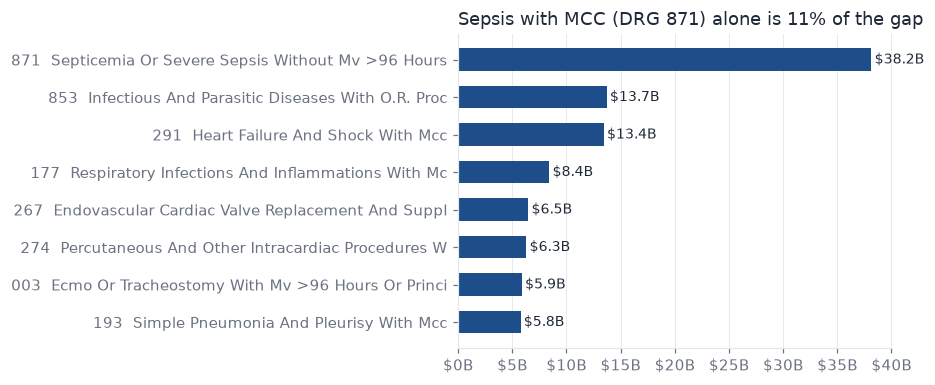

In [7]:
top = sql_block("q7_top_service_lines").head(8)
top["label"] = top.drg_code + "  " + top.drg_description.str.title().str.slice(0, 48)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.barh(top.label[::-1], top.charge_gap[::-1], color=ACCENT, height=.6)
for y, v in enumerate(top.charge_gap[::-1]): ax.text(v + 3e8, y, f"${v/1e9:.1f}B", va="center", color=INK, fontsize=9)
ax.xaxis.set_major_formatter(B); ax.grid(axis="y", visible=False)
ax.set_title("Sepsis with MCC (DRG 871) alone is 11% of the gap", loc="left", color=INK)
plt.tight_layout(); plt.savefig(FIG / "03_top_service_lines.png"); plt.show()

## 5. Why does the gap exist? Charges, not payments, differ between hospitals
Payment-to-charge ratio (PCR) = payment index / charge index. If the gap were a *payment* problem, hospitals would differ
mostly in what they are paid. Decomposing the variation tests that.

In [8]:
lc, lp = np.log(prov.charge_index), np.log(prov.payment_index)
v_pcr = np.var(lp - lc)
decomp = pd.Series({
    "Variation in charges set by the hospital": np.var(lc) / v_pcr,
    "Variation in payments received": np.var(lp) / v_pcr,
    "Overlap (high chargers also paid a bit more)": -2 * np.cov(lc, lp)[0, 1] / v_pcr})
print((decomp * 100).round(1).to_string())
print(f"\nSpread (std of log index): charges {lc.std():.2f} vs payments {lp.std():.2f}  ->  charges vary {lc.std()/lp.std():.1f}x more")

Variation in charges set by the hospital        97.5
Variation in payments received                  20.8
Overlap (high chargers also paid a bit more)   -18.3

Spread (std of log index): charges 0.52 vs payments 0.24  ->  charges vary 2.2x more


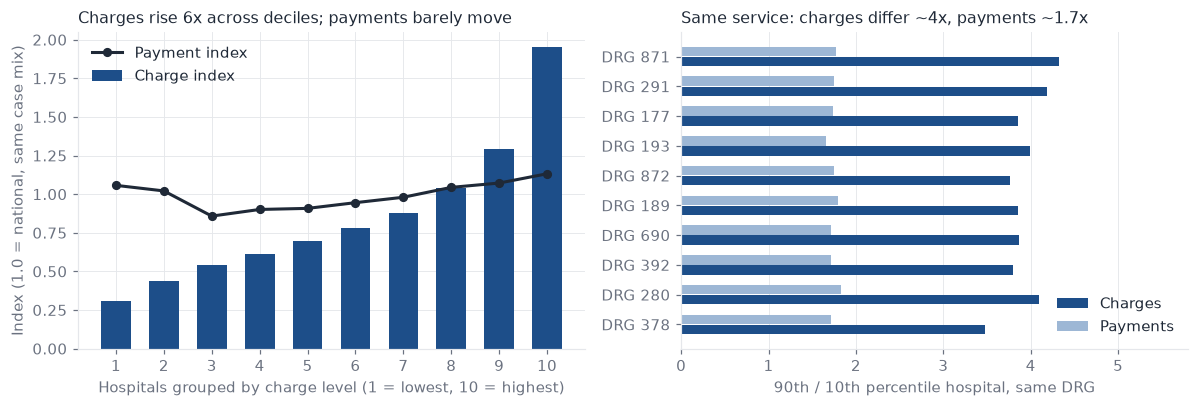

In [9]:
dec = sql_block("q3_charge_index_deciles")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(dec.charge_decile, dec.charge_index, color=ACCENT, width=.62, label="Charge index")
ax[0].plot(dec.charge_decile, dec.payment_index, color=INK, lw=2, marker="o", ms=5, label="Payment index")
ax[0].set_xticks(range(1, 11)); ax[0].set_xlabel("Hospitals grouped by charge level (1 = lowest, 10 = highest)")
ax[0].set_title("Charges rise 6x across deciles; payments barely move", loc="left", color=INK, fontsize=10.5)
ax[0].legend(frameon=False, loc="upper left"); ax[0].set_ylabel("Index (1.0 = national, same case mix)")
spread = sql_block("q6_same_drg_spread")
y = np.arange(len(spread))
ax[1].barh(y + .17, spread.charge_p90_p10, height=.32, color=ACCENT, label="Charges")
ax[1].barh(y - .17, spread.payment_p90_p10, height=.32, color=LIGHT, label="Payments")
ax[1].set_yticks(y); ax[1].set_yticklabels("DRG " + spread.drg_code); ax[1].invert_yaxis()
ax[1].set_xlabel("90th / 10th percentile hospital, same DRG"); ax[1].grid(axis="y", visible=False)
ax[1].set_title("Same service: charges differ ~4x, payments ~1.7x", loc="left", color=INK, fontsize=10.5)
ax[1].set_xlim(0, 5.8); ax[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "04_why_charges_drive_gap.png"); plt.show()

**Reading:** about 97% of the hospital-to-hospital variation in payment-to-charge ratio comes from how hospitals *price*, not
from how they are *paid*. Maryland, which regulates hospital prices, has a ratio of ~90% against ~20% nationally, which
confirms the gap is a list-price artefact rather than lost revenue.

## 6. Geography and setting

,state_code,charge_index,payment_index,pcr
0,NV,1.75,0.97,0.113
1,CA,1.64,1.27,0.158
2,AK,1.49,1.32,0.181
3,NJ,1.36,1.06,0.160
4,CO,1.31,0.93,0.145


     setting  hospitals  discharges  charge_index  payment_index   pcr
Metropolitan       2146     4548555          1.02           1.01 0.202
Micropolitan        537      335883          0.70           0.89 0.262
  Small town        211       41093          0.64           0.94 0.308
Unclassified         12       18988          1.03           0.92 0.181
       Rural         39       15806          0.74           0.90 0.250


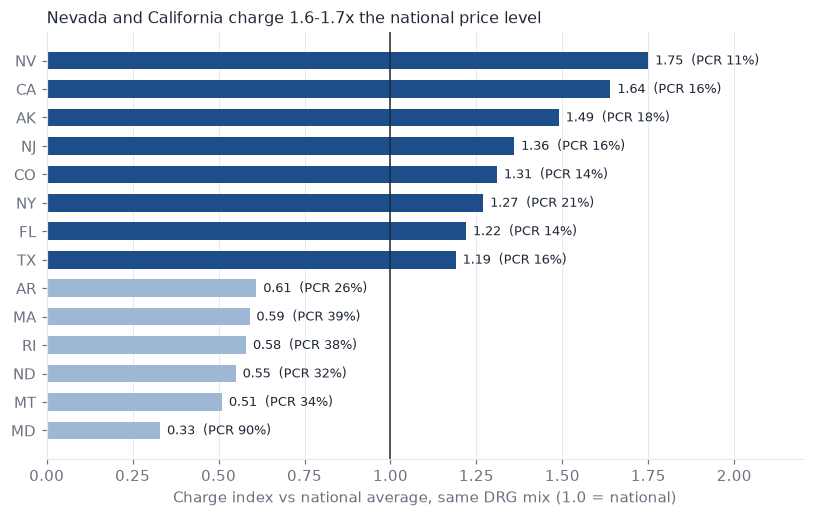

In [10]:
st = sql_block("q4_state_ranking"); display(st.head(5)[["state_code","charge_index","payment_index","pcr"]])
print(sql_block("q5_setting_comparison").to_string(index=False))
sel = pd.concat([st.head(8), st.tail(6)]).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
colors = [ACCENT if v > 1 else LIGHT for v in sel.charge_index]
ax.barh(sel.state_code, sel.charge_index, color=colors, height=.62)
ax.axvline(1, color=INK, lw=1)
for yy, (ci, pc) in enumerate(zip(sel.charge_index, sel.pcr)): ax.text(ci + .02, yy, f"{ci:.2f}  (PCR {pc:.0%})", va="center", fontsize=8.5, color=INK)
ax.set_xlim(0, 2.2); ax.grid(axis="y", visible=False)
ax.set_title("Nevada and California charge 1.6-1.7x the national price level", loc="left", color=INK, fontsize=10.5)
ax.set_xlabel("Charge index vs national average, same DRG mix (1.0 = national)")
plt.tight_layout(); plt.savefig(FIG / "05_state_charge_index.png"); plt.show()

## 7. Hospital segmentation (k-means)
Features: log volume, log charge index, log payment index, DRG breadth, non-metropolitan flag. Standardised, k=5 chosen for
business interpretability (silhouette for k=3..7 is shown; a 4-cluster solution merges a distinct high-payment group).

In [11]:
X = pd.DataFrame({"volume": np.log10(prov.discharges), "charge": np.log(prov.charge_index),
                  "payment": np.log(prov.payment_index), "breadth": np.log10(prov.drgs_billed),
                  "nonmetro": (prov.setting != "Metropolitan").astype(int)})
Z = StandardScaler().fit_transform(X)
print({k_: round(silhouette_score(Z, KMeans(k_, n_init=20, random_state=7).fit_predict(Z)), 3) for k_ in range(3, 8)})
prov["cluster"] = KMeans(5, n_init=20, random_state=7).fit_predict(Z)
prof = prov.groupby("cluster").agg(hospitals=("provider_id", "count"), median_discharges=("discharges", "median"),
        median_drgs=("drgs_billed", "median"), charge_index=("charge_index", "median"), payment_index=("payment_index", "median"),
        nonmetro=("setting", lambda s: (s != "Metropolitan").mean()), gap=("charge_gap", "sum"))
def name(r):
    if r.nonmetro > .5: return "Community & rural hospitals"
    if r.payment_index > 1.4: return "High-payment complex-care centres"
    if r.median_discharges < 500: return "Small metro hospitals"
    return "Large high-charge systems" if r.charge_index > 1.15 else "Large mainstream systems"
prof["segment"] = prof.apply(name, axis=1)
assert prof.segment.is_unique, prof
prov["segment"] = prov.cluster.map(prof.segment)
seg = prov.groupby("segment").agg(hospitals=("provider_id", "count"), discharges=("discharges", "sum"),
      charge_gap=("charge_gap", "sum"), total_charges=("total_charges", "sum"), total_payment=("total_payment", "sum"),
      median_charge_index=("charge_index", "median"), median_payment_index=("payment_index", "median"))
seg["pcr"] = seg.total_payment / seg.total_charges; seg["share_of_gap"] = seg.charge_gap / seg.charge_gap.sum()
seg = seg.sort_values("share_of_gap", ascending=False); display(seg.round(3))

{3: 0.348, 4: 0.306, 5: 0.29, 6: 0.29, 7: 0.286}


,hospitals,discharges,charge_gap,total_charges,total_payment,median_charge_index,median_payment_index,pcr,share_of_gap
segment,,,,,,,,,
Large high-charge systems,656,1902657,2.162611e+11,2.561260e+11,3.986489e+10,1.358,0.986,0.156,0.629
Large mainstream systems,932,2554466,1.082612e+11,1.484031e+11,4.014183e+10,0.682,0.854,0.270,0.315
Community & rural hospitals,745,311917,9.527643e+09,1.331317e+10,3.785523e+09,0.513,0.880,0.284,0.028
High-payment complex-care centres,157,93376,5.390673e+09,8.580313e+09,3.189640e+09,0.987,1.687,0.372,0.016
Small metro hospitals,455,97909,4.317523e+09,5.746746e+09,1.429223e+09,0.667,0.827,0.249,0.013


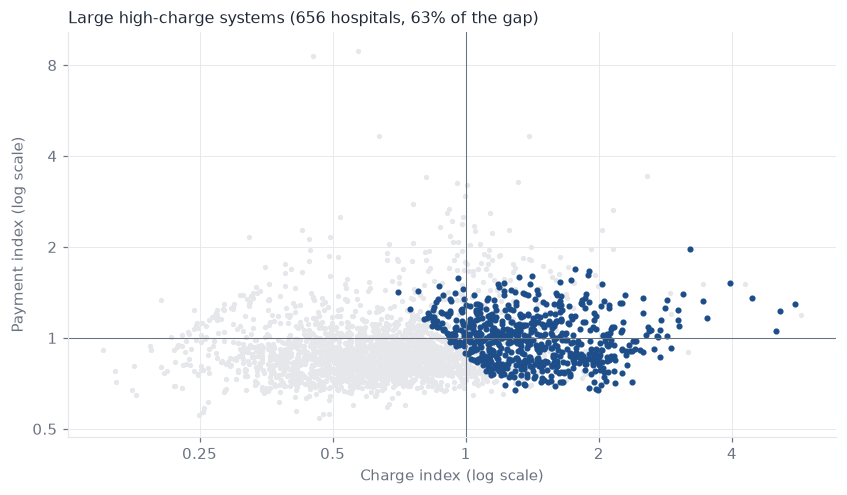

In [12]:
fig, ax = plt.subplots(figsize=(7.8, 4.6))
ax.scatter(prov.charge_index, prov.payment_index, s=6, color=GRID, zorder=1)
hi = prov[prov.segment == "Large high-charge systems"]
ax.scatter(hi.charge_index, hi.payment_index, s=9, color=ACCENT, zorder=2)
ax.set_xscale("log"); ax.set_yscale("log"); ax.axvline(1, color=MUTED, lw=.7); ax.axhline(1, color=MUTED, lw=.7)
ax.set_xticks([.25, .5, 1, 2, 4]); ax.set_xticklabels(["0.25", "0.5", "1", "2", "4"]); ax.set_yticks([.5, 1, 2, 4, 8]); ax.set_yticklabels(["0.5", "1", "2", "4", "8"]); ax.minorticks_off()
ax.set_xlabel("Charge index (log scale)"); ax.set_ylabel("Payment index (log scale)")
ax.set_title(f"Large high-charge systems ({len(hi)} hospitals, {hi.charge_gap.sum()/prov.charge_gap.sum():.0%} of the gap)", loc="left", color=INK, fontsize=10.5)
plt.tight_layout(); plt.savefig(FIG / "06_segments.png"); plt.show()

## 8. Documentation-capture screen (the one lever hospitals control)
Medicare pays by DRG severity tier (MCC > CC > none). A hospital whose share of top-tier cases is **lower than peers'**
may be under-documenting complications and comorbidities. The SQL view values every case at the *national* payment of its
DRG, so only the case-mix difference remains (wage index, teaching status and DSH are excluded by construction).
This is a **screen for clinical-documentation review, not a forecast**: lighter mixes can be legitimate.

In [13]:
scr = q("SELECT * FROM v_provider_severity_screen")
pos = scr[scr.severity_shortfall > 0]
print(f"{len(scr):,} hospitals screened (>=300 tiered discharges, >=10 families); net shortfall ${scr.severity_shortfall.sum()/1e6:,.0f}M (benchmark is balanced by design)")
print(f"{len(pos):,} hospitals below peers; their combined shortfall = ${pos.severity_shortfall.sum()/1e6:,.0f}M "
      f"= {pos.severity_shortfall.sum()/scr.expected_value.sum():.2%} of tiered payments")
for thr in (0, .01, .02, .03):
    s = scr[scr.shortfall_pct >= thr]; print(f"  shortfall >= {thr:.0%} of expected: {len(s):4d} hospitals, ${s.severity_shortfall.sum()/1e6:,.0f}M")

1,996 hospitals screened (>=300 tiered discharges, >=10 families); net shortfall $-42M (benchmark is balanced by design)
981 hospitals below peers; their combined shortfall = $744M = 1.07% of tiered payments
  shortfall >= 0% of expected:  981 hospitals, $744M
  shortfall >= 1% of expected:  709 hospitals, $693M
  shortfall >= 2% of expected:  473 hospitals, $555M
  shortfall >= 3% of expected:  281 hospitals, $377M


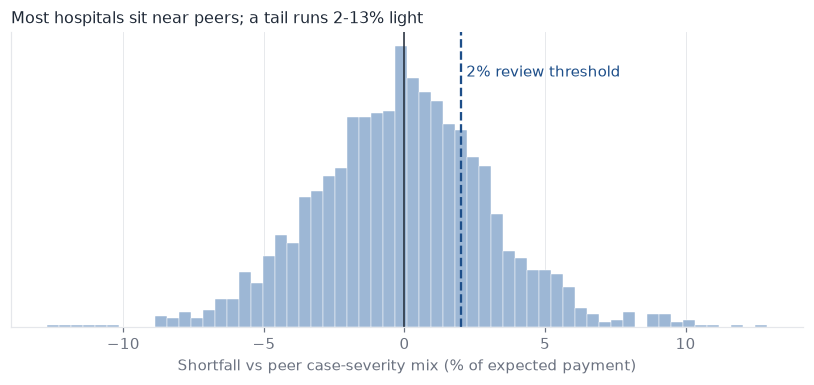

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(scr.shortfall_pct * 100, bins=60, color=LIGHT, edgecolor="white", linewidth=.3)
ax.axvline(0, color=INK, lw=1); ax.axvline(2, color=ACCENT, lw=1.5, ls="--")
ax.text(2.2, ax.get_ylim()[1] * .85, "2% review threshold", color=ACCENT)
ax.set_xlabel("Shortfall vs peer case-severity mix (% of expected payment)"); ax.set_yticks([])
ax.set_title("Most hospitals sit near peers; a tail runs 2-13% light", loc="left", color=INK, fontsize=10.5)
plt.tight_layout(); plt.savefig(FIG / "07_severity_screen.png"); plt.show()

## 9. Exports for Excel and Power BI

In [15]:
# --- Power BI star schema (names, not just codes) ---------------------------------
pb = ROOT / "powerbi" / "data"; pb.mkdir(parents=True, exist_ok=True)
q("SELECT * FROM dim_state").to_csv(pb / "dim_state.csv", index=False)
q("SELECT g.*, 1 AS _ FROM dim_geography g").drop(columns="_").to_csv(pb / "dim_geography.csv", index=False)
prov_dim = q("""SELECT p.*, s.state_name, s.census_region, COALESCE(g.setting,'Unclassified') AS setting
                 FROM dim_provider p JOIN dim_state s USING (state_code) LEFT JOIN dim_geography g USING (ruca_code)""")
prov_dim = prov_dim.merge(prov[["provider_id", "segment"]], on="provider_id", how="left")
prov_dim.to_csv(pb / "dim_provider.csv", index=False)
q("SELECT d.*, b.hospitals, b.nat_charge_per_discharge, b.nat_payment_per_discharge, b.nat_pcr FROM dim_drg d JOIN v_drg_benchmark b USING (drg_code)").to_csv(pb / "dim_drg.csv", index=False)   # benchmark merged in: one relationship hop for DAX
q("""SELECT provider_id, drg_code, total_discharges, avg_submitted_charge, avg_total_payment, avg_medicare_payment,
        total_charges, total_payment, total_medicare_payment, charge_gap FROM v_fact""").to_csv(pb / "fact_discharge.csv", index=False)
scr.to_csv(pb / "provider_severity_screen.csv", index=False)
prov.to_csv(OUT / "provider_scorecard.csv", index=False)       # hospital scorecard with segment
seg.reset_index().to_csv(OUT / "segment_summary.csv", index=False)

# --- Excel scenario model input: screened hospitals, largest shortfall first ---------
xl = scr.sort_values("severity_shortfall", ascending=False)[["provider_id", "provider_name", "state_code", "setting",
        "tiered_discharges", "top_tier_share", "peer_expected_top_tier_share", "expected_value", "severity_shortfall", "shortfall_pct"]]
xl.to_csv(OUT / "excel_severity_inputs.csv", index=False)
print("exported:", sorted(p.name for p in pb.glob("*.csv")))

exported: ['dim_drg.csv', 'dim_geography.csv', 'dim_provider.csv', 'dim_state.csv', 'drg_benchmark.csv', 'fact_discharge.csv', 'provider_severity_screen.csv']


## 10. What this means
1. The headline gap ($344B on $432B of charges) is a **list-price artefact**: it is not recoverable revenue.
2. Charge-setting explains ~97% of the variation in payment-to-charge ratios; payments barely differ for the same case mix.
3. The gap is concentrated: 240 hospitals and 25 DRGs make up half of it, and the 656 large high-charge systems hold 63% of it.
4. The one payment lever hospitals control is **severity documentation**, worth up to ~$0.7B across 981 screened hospitals
   (~$0.55B at a 2% review threshold; every dollar would require clinical validation), modelled in `excel/healthcare_opportunity_model.xlsx`.